In [1]:
# Veri analizi için gerekli kütüphaneleri içe aktar
import pandas as pd
import numpy as np

# Ekranda gösterilecek ondalık basamak sayısını 3 ile sınırla (okunabilirlik için)
pd.set_option("display.float_format", "{:.3f}".format)

# Veriyi oku; notebook "notebooks/" içinde olduğu için veriye "../data/" ile ulaşıyoruz
# index_col=0: dosyadaki ilk sütun sadece satır numarası olduğu için indeks yapıyoruz
df = pd.read_csv("../data/cs-training.csv", index_col=0)

# Kaç satır ve kaç sütun var?
print("Veri boyutu (satır, sütun):", df.shape)

# İlk 5 satıra bak
df.head()

Veri boyutu (satır, sütun): (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766,45,2,0.803,9120.000,13,0,6,0,2.000
2,0,0.957,40,0,0.122,2600.000,4,0,0,0,1.000
3,0,0.658,38,1,0.085,3042.000,2,1,0,0,0.000
4,0,0.234,30,0,0.036,3300.000,5,0,0,0,0.000
5,0,0.907,49,1,0.025,63588.000,7,0,1,0,0.000


In [2]:
# Sütunların ne anlama geldiğini açıklayan Excel dosyasını oku
sozluk = pd.read_excel("../data/Data Dictionary.xls")

# Açıklamaların tamamı görünsün diye sütun genişliği sınırını kaldır
pd.set_option("display.max_colwidth", None)

# Sözlüğü göster
sozluk

/tmp/ipykernel_9358/1132254510.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  sozluk = pd.read_excel("../data/Data Dictionary.xls")


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquency or worse,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans divided by the sum of credit limits,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days past due but no worse in the last 2 years.,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs divided by monthy gross income",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards),integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or more past due.,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans including home equity lines of credit,integer


In [3]:
# Her sütunun tipini ve dolu satır sayısını göster
df.info()

# Her sütunda kaç eksik değer var?
eksik = df.isnull().sum()

# Eksik değerlerin yüzdesini hesapla
eksik_yuzde = (df.isnull().mean() * 100).round(2)

# İkisini yan yana tabloya koy, sadece eksik olanları göster
pd.DataFrame({"eksik_sayi": eksik, "eksik_yuzde": eksik_yuzde})[eksik > 0]

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

,eksik_sayi,eksik_yuzde
MonthlyIncome,29731,19.820
NumberOfDependents,3924,2.620


In [4]:
# Hedef değişkende kaç tane 0 ve kaç tane 1 var?
print(df["SeriousDlqin2yrs"].value_counts())

# Aynısını yüzde olarak göster
print(df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100)

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0   93.316
1    6.684
Name: proportion, dtype: float64


In [5]:
# Sayısal sütunların özet istatistikleri (.T: tabloyu çevirir, okumayı kolaylaştırır)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.000,0.067,0.250,0.000,0.000,0.000,0.000,1.000
RevolvingUtilizationOfUnsecuredLines,150000.000,6.048,249.755,0.000,0.030,0.154,0.559,50708.000
age,150000.000,52.295,14.772,0.000,41.000,52.000,63.000,109.000
NumberOfTime30-59DaysPastDueNotWorse,150000.000,0.421,4.193,0.000,0.000,0.000,0.000,98.000
DebtRatio,150000.000,353.005,2037.819,0.000,0.175,0.367,0.868,329664.000
MonthlyIncome,120269.000,6670.221,14384.674,0.000,3400.000,5400.000,8249.000,3008750.000
NumberOfOpenCreditLinesAndLoans,150000.000,8.453,5.146,0.000,5.000,8.000,11.000,58.000
NumberOfTimes90DaysLate,150000.000,0.266,4.169,0.000,0.000,0.000,0.000,98.000
NumberRealEstateLoansOrLines,150000.000,1.018,1.130,0.000,0.000,1.000,2.000,54.000
NumberOfTime60-89DaysPastDueNotWorse,150000.000,0.240,4.155,0.000,0.000,0.000,0.000,98.000


In [6]:
# Yaşı 0 olan (imkansız) satırlar kaç tane?
print("age == 0:", (df["age"] == 0).sum())

# Üç gecikme sütununda en büyük değerler ve kaçar satırda göründükleri
gecikme_sutunlari = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]
for sutun in gecikme_sutunlari:
    print(sutun)
    # sort_index: değerleri küçükten büyüğe sıralar, tail(5): en büyük 5 değeri gösterir
    print(df[sutun].value_counts().sort_index().tail(5))
    print()

# Limit kullanım oranı 1'den büyük olan satır sayısı
print("RevolvingUtilization > 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())

# DebtRatio'su 100'ün üzerinde olan satır sayısı
print("DebtRatio > 100:", (df["DebtRatio"] > 100).sum())

# Bu uçuk DebtRatio satırlarının kaçında gelir bilgisi eksik? (0-1 arası oran)
print("Bu satırlarda MonthlyIncome eksik oranı:",
      df[df["DebtRatio"] > 100]["MonthlyIncome"].isnull().mean())

age == 0: 1
NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64

RevolvingUtilization > 1: 3321
DebtRatio > 100: 24380
Bu satırlarda MonthlyIncome eksik oranı: 0.9308039376538146


In [7]:
# 3 gecikme sütununun adları
gecikme = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]

# Herhangi bir gecikme sütununda 96 veya 98 olan satırlar
ozel = df[gecikme].isin([96, 98]).any(axis=1)
print("96/98 içeren satır sayısı:", ozel.sum())

# Üç sütunda birden mi görünüyor? (hepsi aynı satırlar mı)
print("Üçünde birden 96/98 olan satır:", df[gecikme].isin([96, 98]).all(axis=1).sum())

# Bu satırlarda temerrüt oranı, diğerlerine göre nasıl? (yüzde)
print("96/98'li satırlarda temerrüt %:", round(df.loc[ozel, "SeriousDlqin2yrs"].mean() * 100, 2))
print("Diğer satırlarda temerrüt %:", round(df.loc[~ozel, "SeriousDlqin2yrs"].mean() * 100, 2))

# Limit kullanım oranının dağılımı: yüzdelikler (0.999 = en uçtaki %0,1)
oran = "RevolvingUtilizationOfUnsecuredLines"
print(df[oran].quantile([0.5, 0.9, 0.99, 0.999]))
print("Oran > 10 olan satır sayısı:", (df[oran] > 10).sum())

# Gelir eksik olanlarla dolu olanlar arasında temerrüt oranı ve DebtRatio medyanı
gelir_eksik = df["MonthlyIncome"].isnull()
print("Gelir eksik, temerrüt %:", round(df.loc[gelir_eksik, "SeriousDlqin2yrs"].mean() * 100, 2))
print("Gelir dolu, temerrüt %:", round(df.loc[~gelir_eksik, "SeriousDlqin2yrs"].mean() * 100, 2))
print(df.groupby(gelir_eksik)["DebtRatio"].median())

96/98 içeren satır sayısı: 269
Üçünde birden 96/98 olan satır: 269
96/98'li satırlarda temerrüt %: 54.65
Diğer satırlarda temerrüt %: 6.6
0.500      0.154
0.900      0.981
0.990      1.093
0.999   1571.006
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
Oran > 10 olan satır sayısı: 241
Gelir eksik, temerrüt %: 5.61
Gelir dolu, temerrüt %: 6.95
MonthlyIncome
False      0.296
True    1159.000
Name: DebtRatio, dtype: float64


In [8]:
# Hedef sütun (gerçek değerler)
y = df["SeriousDlqin2yrs"]

# "Hep 0 de" modeli: herkese temerrüde düşmez tahmini
tahmin = np.zeros(len(y))

# Accuracy: tahminin gerçekle eşleştiği satırların oranı
accuracy = (tahmin == y).mean()
print("Accuracy:", round(accuracy * 100, 2))

# Recall: gerçekten 1 olanların kaçını yakaladık? (1 olan satırlarda tahminin 1 olma oranı)
recall = (tahmin[y == 1] == 1).mean()
print("Recall:", round(recall * 100, 2))

Accuracy: 93.32
Recall: 0.0


In [9]:
# Orijinal veriyi bozmamak için kopya üzerinde çalış
df_temiz = df.copy()

# 1) Yaşı 0 olan hatalı satırı sil
df_temiz = df_temiz[df_temiz["age"] > 0]

# 2) Gecikme sütunlarındaki 96/98 özel kodları
gecikme = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]
# Bayrak: satırda 96 veya 98 var mı? (astype(int): True/False -> 1/0)
df_temiz["gecikme_ozel_kod"] = df_temiz[gecikme].isin([96, 98]).any(axis=1).astype(int)
# Sahte sayıları eksik değere (NaN) çevir; bilgi bayrakta saklı kalıyor
df_temiz[gecikme] = df_temiz[gecikme].replace([96, 98], np.nan)

# 3) Gelir eksik mi? Bayrak ekle
df_temiz["gelir_eksik"] = df_temiz["MonthlyIncome"].isnull().astype(int)

# 4) Limit kullanım oranını en fazla 2 olacak şekilde sınırla (uç değerleri kırp)
oran = "RevolvingUtilizationOfUnsecuredLines"
df_temiz[oran] = df_temiz[oran].clip(upper=2)

# Kontrol: satır sayısı (150000 - 1 = 149999 olmalı)
print("Satır sayısı:", len(df_temiz))

# Kontrol: hangi sütunlarda eksik değer var?
eksikler = df_temiz.isnull().sum()
print(eksikler[eksikler > 0])

# DebtRatio incelemesi: gelir eksik (1) ve dolu (0) gruplarında yüzdelik değerler
print(df_temiz.groupby("gelir_eksik")["DebtRatio"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack())

Satır sayısı: 149999
NumberOfTime30-59DaysPastDueNotWorse      269
MonthlyIncome                           29731
NumberOfTimes90DaysLate                   269
NumberOfTime60-89DaysPastDueNotWorse      269
NumberOfDependents                       3924
dtype: int64
             0.100   0.250    0.500    0.750    0.900
gelir_eksik                                          
0            0.022   0.143    0.296    0.483    0.763
1           11.000 123.000 1159.000 2382.000 3785.000


In [10]:
# Gelir eksik olan satırlar (DebtRatio burada muhtemelen oran değil tutar)
eksik_grup = df_temiz[df_temiz["gelir_eksik"] == 1]

# qcut: satırları DebtRatio değerine göre eşit sayıda 4 gruba böler
gruplar = pd.qcut(eksik_grup["DebtRatio"], 4)

# Her grupta temerrüt yüzdesi: yükseldikçe artıyor mu?
print((eksik_grup.groupby(gruplar, observed=True)["SeriousDlqin2yrs"].mean() * 100).round(2))

# Gelir dolu satırlarda DebtRatio'su 1'den büyük olanların oranı (yüzde)
dolu_grup = df_temiz[df_temiz["gelir_eksik"] == 0]
print("Gelir dolu, DebtRatio > 1 oranı %:", round((dolu_grup["DebtRatio"] > 1).mean() * 100, 2))

DebtRatio
(-0.001, 123.0]      4.760
(123.0, 1159.0]      7.830
(1159.0, 2382.0]     4.390
(2382.0, 329664.0]   5.480
Name: SeriousDlqin2yrs, dtype: float64
Gelir dolu, DebtRatio > 1 oranı %: 6.01


In [11]:
# Gelir eksik satırlarda DebtRatio güvenilmez (oran değil tutar gibi): NaN yap
df_temiz.loc[df_temiz["gelir_eksik"] == 1, "DebtRatio"] = np.nan

# Ayırma fonksiyonunu içe aktar
from sklearn.model_selection import train_test_split

# Hedef (y) ve özellikler (X)
y = df_temiz["SeriousDlqin2yrs"]
X = df_temiz.drop(columns=["SeriousDlqin2yrs"])

# %80 eğitim, %20 test. stratify=y: iki parçada da temerrüt oranı aynı kalsın
# random_state=42: her çalıştırmada aynı bölünme gelsin (tekrar üretilebilirlik)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Kontrol: boyutlar ve iki parçadaki temerrüt oranı (yaklaşık %6,7 olmalı)
print("Eğitim:", X_train.shape, "Test:", X_test.shape)
print("Eğitimde temerrüt %:", round(y_train.mean() * 100, 2))
print("Testte temerrüt %:", round(y_test.mean() * 100, 2))

Eğitim: (119999, 12) Test: (30000, 12)
Eğitimde temerrüt %: 6.68
Testte temerrüt %: 6.68


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score

# Pipeline: eksikleri doldur -> ölçekle -> model
# Doldurma ve ölçekleme sadece EĞİTİM verisinden öğrenilir (test verisi sızmaz)
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # eksikleri medyanla doldur
    ("scaler", StandardScaler()),                    # sütunları aynı ölçeğe getir
    ("model", LogisticRegression(
        class_weight="balanced",   # az olan sınıfa (temerrüt) daha fazla ağırlık ver
        max_iter=1000,
        random_state=42,
    )),
])

# Modeli eğitim verisiyle eğit
baseline.fit(X_train, y_train)

# Test verisinde temerrüt olasılığı (1 sınıfının olasılığı: ikinci sütun)
proba = baseline.predict_proba(X_test)[:, 1]
# Varsayılan eşik (0.5) ile sınıf tahmini
tahmin = baseline.predict(X_test)

# Metrikler
print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 4))
print("PR-AUC   :", round(average_precision_score(y_test, proba), 4))
print("Recall   :", round(recall_score(y_test, tahmin), 4))
print("Precision:", round(precision_score(y_test, tahmin), 4))

ROC-AUC  : 0.8607
PR-AUC   : 0.3812
Recall   : 0.7451
Precision: 0.2232


In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Sınıf dengesizliği oranı: kaç tane 0 var, kaç tane 1 var (boosting için ağırlık)
oran = (y_train == 0).sum() / (y_train == 1).sum()

# Karşılaştıracağımız modeller
# Ağaç tabanlı modeller NaN değerleri kendisi işleyebilir, bu yüzden imputer gerekmez
modeller = {
    "LogReg (baseline)": baseline,
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        scale_pos_weight=oran,   # az olan sınıfa ağırlık
        random_state=42, verbose=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=oran, eval_metric="logloss",
        random_state=42, n_jobs=-1,
    ),
}

# 5 parçalı, sınıf oranını koruyan çapraz doğrulama
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sonuclar = []
for ad, model in modeller.items():
    # Çapraz doğrulama: sadece eğitim verisi içinde, ROC-AUC ortalaması ve oynaklığı
    cv_skorlari = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")

    # Tüm eğitim verisiyle eğit, test verisinde değerlendir
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]

    # İş metriği: en riskli %10 müşteriyi işaretlersek, gerçek temerrütlerin kaçını yakalarız?
    n = int(len(y_test) * 0.10)
    en_riskli = np.argsort(proba)[::-1][:n]            # skoru en yüksek n kişinin sırası
    yakalanan = y_test.values[en_riskli].sum() / y_test.sum()

    sonuclar.append({
        "model": ad,
        "cv_roc_auc": round(cv_skorlari.mean(), 4),
        "cv_std": round(cv_skorlari.std(), 4),
        "test_roc_auc": round(roc_auc_score(y_test, proba), 4),
        "test_pr_auc": round(average_precision_score(y_test, proba), 4),
        "top10%_yakalama": round(yakalanan, 4),
    })

# Sonuçları tabloya dök
pd.DataFrame(sonuclar).set_index("model")

,cv_roc_auc,cv_std,test_roc_auc,test_pr_auc,top10%_yakalama
model,,,,,
LogReg (baseline),0.855,0.006,0.861,0.381,0.549
LightGBM,0.861,0.006,0.866,0.395,0.556
XGBoost,0.864,0.006,0.869,0.400,0.557


In [15]:
from sklearn.model_selection import RandomizedSearchCV

# Sınıf ağırlığı: 0'ların sayısının 1'lerin sayısına oranı
agirlik = (y_train == 0).sum() / (y_train == 1).sum()

# Temel model; aranacak parametreler aşağıda değişecek
xgb = XGBClassifier(
    scale_pos_weight=agirlik,   # az olan temerrüt sınıfına ağırlık
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

# Denenecek parametre aralıkları
parametreler = {
    "n_estimators": [200, 400, 600],        # ağaç sayısı
    "learning_rate": [0.02, 0.05, 0.1],     # her ağacın etkisi (küçük = daha yavaş ama dengeli)
    "max_depth": [3, 4, 5, 6],              # ağaç derinliği (büyük = daha karmaşık, aşırı öğrenme riski)
    "min_child_weight": [1, 5, 10],         # bir yaprağın en az kaç "ağırlık" içermesi gerektiği
    "subsample": [0.7, 0.85, 1.0],          # her ağaçta kullanılacak satır oranı
    "colsample_bytree": [0.7, 0.85, 1.0],   # her ağaçta kullanılacak sütun oranı
    "reg_lambda": [1, 5, 10],               # düzenlileştirme (aşırı öğrenmeyi frenler)
}

# Rastgele arama: tüm kombinasyonları değil, 20 rastgele kombinasyonu dener (zaman tasarrufu)
# scoring="average_precision": dengesiz veride PR-AUC'u optimize ediyoruz
arama = RandomizedSearchCV(
    xgb,
    param_distributions=parametreler,
    n_iter=20,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1,         # XGBoost zaten kendi içinde paralel çalışıyor
    verbose=1,
)

# Sadece EĞİTİM verisi üzerinde ara
arama.fit(X_train, y_train)

print("En iyi parametreler:", arama.best_params_)
print("CV PR-AUC (en iyi):", round(arama.best_score_, 4))

# En iyi modeli TEST verisinde bir kez değerlendir
en_iyi = arama.best_estimator_
proba = en_iyi.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("Test PR-AUC :", round(average_precision_score(y_test, proba), 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
En iyi parametreler: {'subsample': 0.85, 'reg_lambda': 5, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.7}
CV PR-AUC (en iyi): 0.4012
Test ROC-AUC: 0.8697
Test PR-AUC : 0.4023


In [16]:
from sklearn.metrics import confusion_matrix

# Baseline modelin test verisindeki sınıf tahminleri (eşik 0.5)
tahmin = baseline.predict(X_test)

# Dört kutuyu çıkar: satırlar gerçek değer, sütunlar tahmin
# ravel(): 2x2 tabloyu düz bir listeye çevirir
tn, fp, fn, tp = confusion_matrix(y_test, tahmin).ravel()

print("TP (doğru yakalanan):", tp)
print("FN (kaçırılan)      :", fn)
print("FP (yanlış alarm)   :", fp)
print("TN (doğru 'riskli değil'):", tn)

TP (doğru yakalanan): 1494
FN (kaçırılan)      : 511
FP (yanlış alarm)   : 5201
TN (doğru 'riskli değil'): 22794


In [17]:
# Baseline modelin test verisindeki temerrüt olasılıkları
proba_baseline = baseline.predict_proba(X_test)[:, 1]

# Farklı eşikler dene: "olasılık eşikten büyükse riskli de"
for esik in [0.3, 0.5, 0.7, 0.9]:
    # Olasılık eşikten büyükse 1 (riskli), değilse 0
    tahmin_esik = (proba_baseline >= esik).astype(int)
    p = precision_score(y_test, tahmin_esik)
    r = recall_score(y_test, tahmin_esik)
    print(f"Eşik {esik}: precision={p:.3f}  recall={r:.3f}")

Eşik 0.3: precision=0.140  recall=0.894
Eşik 0.5: precision=0.223  recall=0.745
Eşik 0.7: precision=0.374  recall=0.540
Eşik 0.9: precision=0.501  recall=0.309


In [18]:
from sklearn.model_selection import cross_val_predict

# Eşiği test verisine bakmadan seçmek için: eğitim verisinde "çapraz tahmin" üret
# Her müşterinin skoru, o müşteriyi hiç görmemiş bir modelden gelir (sızıntı yok)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(en_iyi, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]

# Ayarlı XGBoost'un test verisindeki skorları (eşiği seçtikten sonra kullanacağız)
proba_xgb = en_iyi.predict_proba(X_test)[:, 1]

# Denenecek eşikler: 0.05'ten 0.95'e kadar
esikler = np.arange(0.05, 0.96, 0.05)

def maliyet_hesapla(y_gercek, proba, esik, fn_maliyet):
    # Eşiğe göre tahmin: skor eşikten büyükse "riskli" (1)
    tahmin = (proba >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_gercek, tahmin).ravel()
    # Toplam maliyet: kaçırılan temerrüt x fn_maliyet + yanlış alarm x 1
    return fn * fn_maliyet + fp * 1

satirlar = []
# Temerrüt kaçırmak, yanlış alarmdan kaç kat pahalı? (3, 5, 10 varsayımları)
for fn_oran in [3, 5, 10]:
    # Eğitim çapraz tahminlerinde her eşiğin maliyetini hesapla
    maliyetler = [maliyet_hesapla(y_train.values, oof_proba, e, fn_oran) for e in esikler]
    # En düşük maliyetli eşiği seç (argmin: en küçük değerin sırası)
    secilen = esikler[int(np.argmin(maliyetler))]

    # Seçilen eşiği TEST verisinde bir kez uygula
    tahmin_test = (proba_xgb >= secilen).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, tahmin_test).ravel()
    model_maliyet = fn * fn_oran + fp

    # Model yoksa herkese kredi verilir: tüm temerrütler "kaçırılmış" sayılır
    modelsiz_maliyet = y_test.sum() * fn_oran

    satirlar.append({
        "FN_maliyet_orani": fn_oran,
        "secilen_esik": round(float(secilen), 2),
        "precision": round(tp / (tp + fp), 3),
        "recall": round(tp / (tp + fn), 3),
        "model_maliyeti": int(model_maliyet),
        "modelsiz_maliyet": int(modelsiz_maliyet),
        "tasarruf_%": round((1 - model_maliyet / modelsiz_maliyet) * 100, 1),
    })

pd.DataFrame(satirlar).set_index("FN_maliyet_orani")

,secilen_esik,precision,recall,model_maliyeti,modelsiz_maliyet,tasarruf_%
FN_maliyet_orani,,,,,,
3,0.800,0.424,0.473,4459,6015,25.900
5,0.700,0.350,0.589,6315,10025,37.000
10,0.600,0.278,0.688,9829,20050,51.000


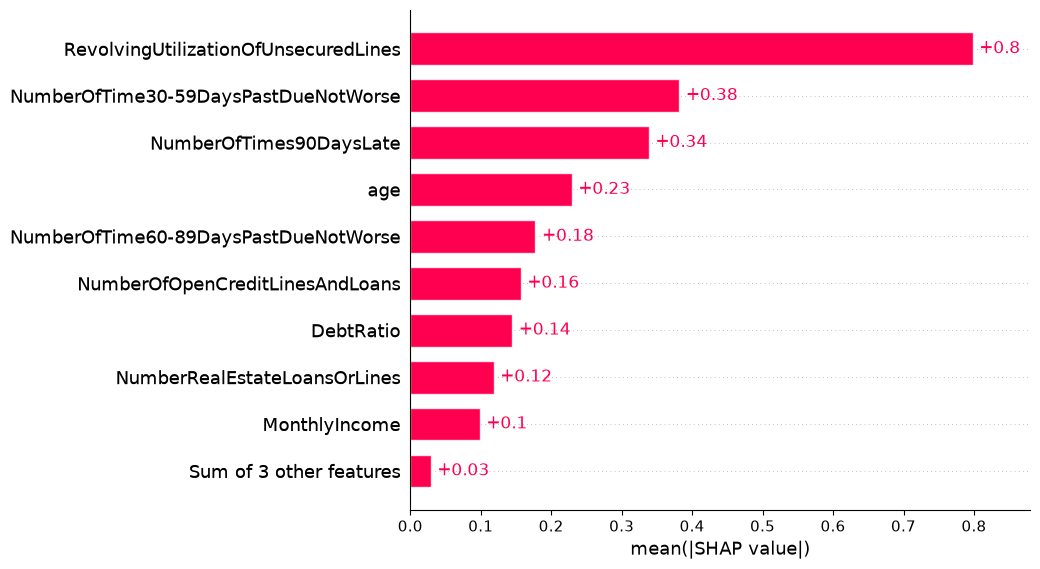

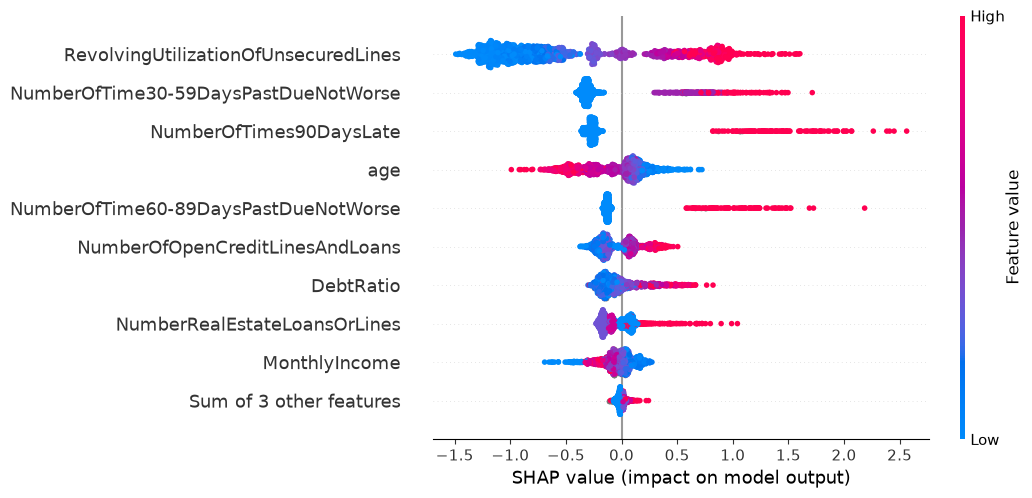

In [19]:
import os
import shap
import matplotlib.pyplot as plt

# Grafikleri kaydedeceğimiz klasör (README'de kullanacağız)
os.makedirs("../reports", exist_ok=True)

# Hız için test verisinden 2000 rastgele müşteri seç
ornek = X_test.sample(2000, random_state=42)

# Ağaç tabanlı modeller için SHAP açıklayıcısı (ayarlı XGBoost)
aciklayici = shap.TreeExplainer(en_iyi)

# Her müşteri ve her özellik için SHAP değerlerini hesapla
shap_degerleri = aciklayici(ornek)

# Grafik 1: Hangi özellik ortalama olarak ne kadar etkili? (çubuk grafik)
shap.plots.bar(shap_degerleri, show=False)
plt.savefig("../reports/shap_onem.png", dpi=150, bbox_inches="tight")
plt.show()

# Grafik 2: Her nokta bir müşteri; renk özelliğin değeri, x ekseni riske etkisi
shap.plots.beeswarm(shap_degerleri, show=False)
plt.savefig("../reports/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

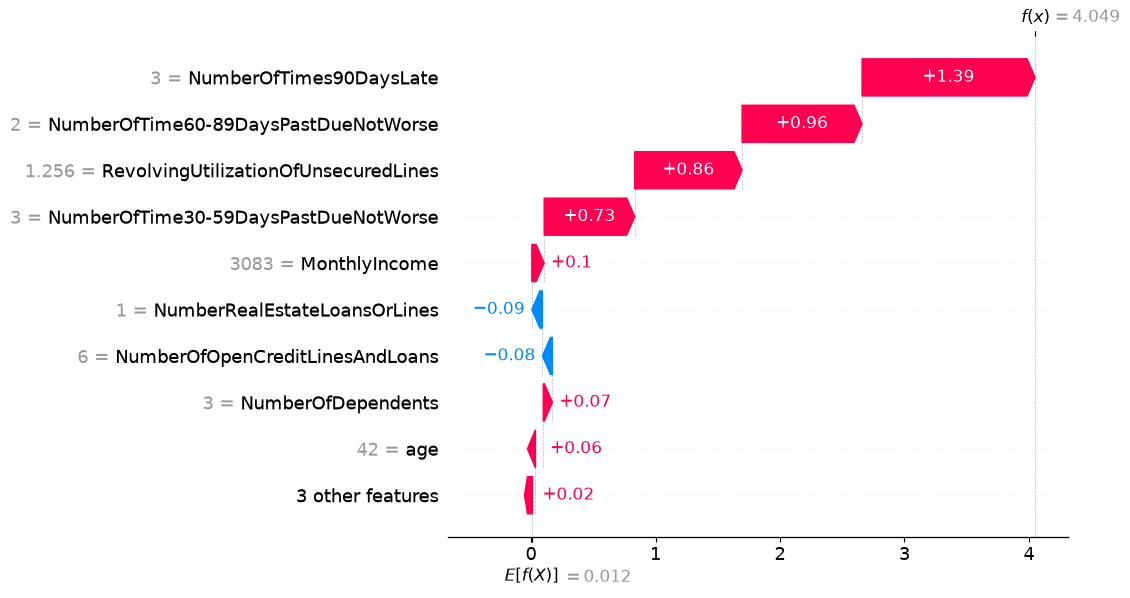

In [20]:
# 2000 örneklik grupta modelin en yüksek risk verdiği müşterinin sırasını bul
skorlar = en_iyi.predict_proba(ornek)[:, 1]
en_riskli_sira = int(np.argmax(skorlar))

# Waterfall grafiği: bu müşteri için her özelliğin katkısını adım adım gösterir
shap.plots.waterfall(shap_degerleri[en_riskli_sira], show=False)
plt.savefig("../reports/shap_tek_musteri.png", dpi=150, bbox_inches="tight")
plt.show()